In [85]:
#---------------------------------------------------------------------------------------------------------------

#IMPORTS

import sqlite3
import pandas as pd
import matplotlib.pyplot as plt


In [86]:
connection = sqlite3.connect("Chinook_Sqlite.sqlite")
print(connection)
cursor = connection.cursor()
print(cursor)


In [87]:
print(cursor.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall())


[('Album',), ('Artist',), ('Customer',), ('Employee',), ('Genre',), ('Invoice',), ('InvoiceLine',), ('MediaType',), ('Playlist',), ('PlaylistTrack',), ('Track',)]


In [88]:
#---------------------------------------------------------------------------------------------------------------

print(cursor.execute("SELECT Track.Name, SUM(InvoiceLine.Quantity) FROM Track JOIN InvoiceLine ON Track.TrackID = InvoiceLine.TrackID GROUP BY Track.Name ORDER BY SUM(InvoiceLine.Quantity) DESC LIMIT 10").fetchall())
print()
print(cursor.execute("SELECT BillingCountry, SUM(Total) FROM Invoice GROUP BY BillingCountry ORDER BY SUM(Total) DESC LIMIT 1").fetchall())
print()
print(cursor.execute("SELECT SupportRepID, COUNT(SupportRepID) FROM Customer GROUP BY SupportRepID").fetchall())


[('The Trooper', 5), ('Untitled', 4), ('The Number Of The Beast', 4), ('Sure Know Something', 4), ('Hallowed Be Thy Name', 4), ('Eruption', 4), ('Where Eagles Dare', 3), ('Welcome Home (Sanitarium)', 3), ('Sweetest Thing', 3), ('Surrender', 3)]

[('USA', 523.06)]

[(3, 21), (4, 20), (5, 18)]


In [89]:
#---------------------------------------------------------------------------------------------------------------

ten_best_selling_tracks = "SELECT Track.Name, SUM(InvoiceLine.Quantity) FROM Track JOIN InvoiceLine ON Track.TrackID = InvoiceLine.TrackID GROUP BY Track.Name ORDER BY SUM(InvoiceLine.Quantity) DESC LIMIT 10"
top_revenue_country = "SELECT BillingCountry, SUM(Total) FROM Invoice GROUP BY BillingCountry ORDER BY SUM(Total) DESC LIMIT 1"
top_performing_sales_employee = "SELECT SupportRepID, COUNT(SupportRepID) FROM Customer GROUP BY SupportRepID ORDER BY COUNT(SupportRepID) DESC LIMIT 1"

BestSellingTracksDataFrame = pd.read_sql_query(ten_best_selling_tracks, connection)
RevenueCountryDataFrame = pd.read_sql_query(top_revenue_country, connection)
SalesEmployeeDataFrame = pd.read_sql_query(top_performing_sales_employee, connection)

BestSellingTracksDataFrame.columns = ["Track Name", "| Total Sold"]
RevenueCountryDataFrame.columns = ["Country", "| Total Revenue"]
SalesEmployeeDataFrame.columns = ["Employee ID", "| Number of Customers"]

print()
print(BestSellingTracksDataFrame.head())
print()
print("=========================================================")
print()
print(RevenueCountryDataFrame.head())
print()
print("=========================================================")
print()
print(SalesEmployeeDataFrame.head())



                Track Name  | Total Sold
0              The Trooper             5
1                 Untitled             4
2  The Number Of The Beast             4
3      Sure Know Something             4
4     Hallowed Be Thy Name             4


  Country  | Total Revenue
0     USA           523.06


   Employee ID  | Number of Customers
0            3                     21


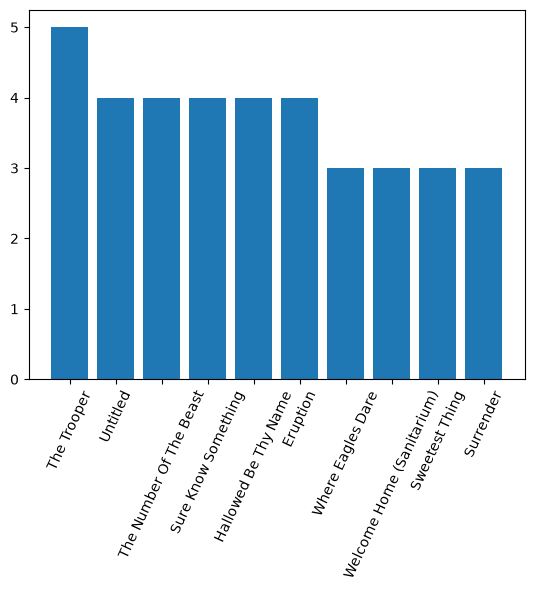

In [90]:
#---------------------------------------------------------------------------------------------------------------

plt.bar(BestSellingTracksDataFrame["Track Name"], BestSellingTracksDataFrame["| Total Sold"])
plt.xticks(rotation=65);